# 08 · Credit-Increase Scenario Score & Decision Explanation
> **Demonstrative scenario framework, not a banking underwriting policy.** The dataset contains no credit-increase requests or outcomes. The *requested increase* is a hypothetical, configurable scenario amount.

Idea (from the senior): **a customer's historical scale decides how big a future request really is.** A request is judged against the customer's own demonstrated behaviour (their typical monthly payment, their current limit), never by its absolute size. Any fixed amount used below (10k, 30k, …) is only an example; the score itself only ever sees ratios.

Inputs to the score:
* the calibrated default probability from notebook 07 (out-of-sample for every customer);
* historical behaviour validated in notebook 03 (lateness, payment coverage, utilization);
* scenario-relative features (request ÷ typical payment, request ÷ limit).

**Setup.** Neo4j is used only to pull graph evidence for individual explanations.

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
from credit_kg import config as C
import copy, subprocess
from scipy.stats import spearmanr
from credit_kg import scoring as S, graph as G, stats as ST
cfg = S.load_config()
driver = G.get_driver()

**The scoring rules, in one table.** Every weight and breakpoint lives in `config/scoring.yaml`. The *anchor* column says where each rule comes from: a validated data pattern, or (for request ÷ limit) an explicit policy assumption.

In [2]:
pd.DataFrame({k: {"what it measures": v["label"], "weight": v["weight"], "breakpoints (x -> sub-score)": list(zip(v.get("x", []), v.get("y", []))) or "1 - late/6, halved if latest month late",
                   "anchor": v["anchor"]} for k, v in cfg["components"].items()}).T

,what it measures,weight,breakpoints (x -> sub-score),anchor
model_risk,predicted default risk (calibrated),0.3,"[(0.1, 1.0), (0.6, 0.0)]",calibrated PD already equals an expected defau...
repayment,"repayment record (late months, latest status)",0.2,"1 - late/6, halved if latest month late",notebook 03 H2 (11.5% default at 0 late months...
coverage,payment coverage of previous statements,0.15,"[(0.0, 0.0), (0.1, 0.4), (0.5, 0.8), (0.99, 1.0)]","notebook 03 H3 (58% default at 0 coverage, ~25..."
payback,request vs typical demonstrated payment (payba...,0.2,"[(1, 1.0), (3, 0.85), (10, 0.5), (30, 0.0)]",notebook 03 H10 default rate by payback band -...
request_vs_limit,request size vs current limit,0.1,"[(0.25, 1.0), (1.0, 0.3), (2.0, 0.0)]",policy assumption (not derived from data) - la...
utilization,current utilization (U-shape aware),0.05,"[(0.0, 0.9), (0.1, 1.0), (0.5, 1.0), (0.9, 0.3...",notebook 02/03 H1 (U-shape; lowest default at ...


**Where the breakpoints come from.** Default rates by bucket from notebook 03 (training data) for the three data-anchored components: lateness, coverage and request ÷ typical payment.

In [3]:
vb = pd.read_csv(C.TABLES / "pattern_validation_buckets.csv")
keep = {"H2  more late months -> more default": "late months", "H3  higher payment coverage -> less default": "median coverage",
        "H10 30k request is large vs typical payment -> more default": "30k ÷ typical payment"}
vb[vb.hypothesis.isin(keep)].assign(component=lambda t: t.hypothesis.map(keep))[["component", "bucket", "n", "default_rate"]].reset_index(drop=True)

,component,bucket,n,default_rate
0,late months,0,15896,0.1151
1,late months,1,3572,0.2996
2,late months,2,1532,0.3995
3,late months,3,936,0.5032
4,late months,4,767,0.5802
5,late months,5,237,0.5992
6,late months,6,1060,0.6972
7,median coverage,"(-inf, 0.0]",622,0.5772
8,median coverage,"(0.0, 0.05]",8071,0.2521
9,median coverage,"(0.05, 0.1]",4051,0.2466


**Load the inputs**: baseline behaviour features, calibrated PD and graph features for all 30,000 customers.

In [4]:
inp = S.load_scoring_inputs()
inp[S.REQUIRED + ["pd"]].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
customer_id,30000.0,15000.500,8660.398,1.0,7500.750,15000.500,22500.250,30000.000
credit_limit,30000.0,167484.323,129747.662,10000.0,50000.000,140000.000,240000.000,1000000.000
pd,30000.0,0.222,0.200,0.0,0.090,0.149,0.267,1.000
late_months,30000.0,0.834,1.554,0.0,0.000,0.000,1.000,6.000
status_latest,30000.0,-0.017,1.124,-2.0,-1.000,0.000,0.000,8.000
coverage_median,30000.0,0.387,0.433,0.0,0.042,0.082,1.000,1.000
pay_median,30000.0,3287.268,7134.277,0.0,725.375,1750.000,3950.000,747276.000
util_latest,30000.0,0.424,0.411,0.0,0.022,0.314,0.830,6.455
inactive_flag,30000.0,0.136,0.342,0.0,0.000,0.000,0.000,1.000
pd,30000.0,0.222,0.200,0.0,0.090,0.149,0.267,1.000


## Relativity first
**One absolute amount, many different meanings.** The same example amount (30,000) expressed in each customer's *own* units: months of their typical payment, and share of their current limit. Note the log scale: the same number is less than one month of payments for some customers and years of payments for others.

,payback months,share of limit
percentile,,
0.05,2.60,0.07
0.25,6.81,0.12
0.50,15.00,0.21
0.75,27.75,0.60
0.95,92.02,1.50


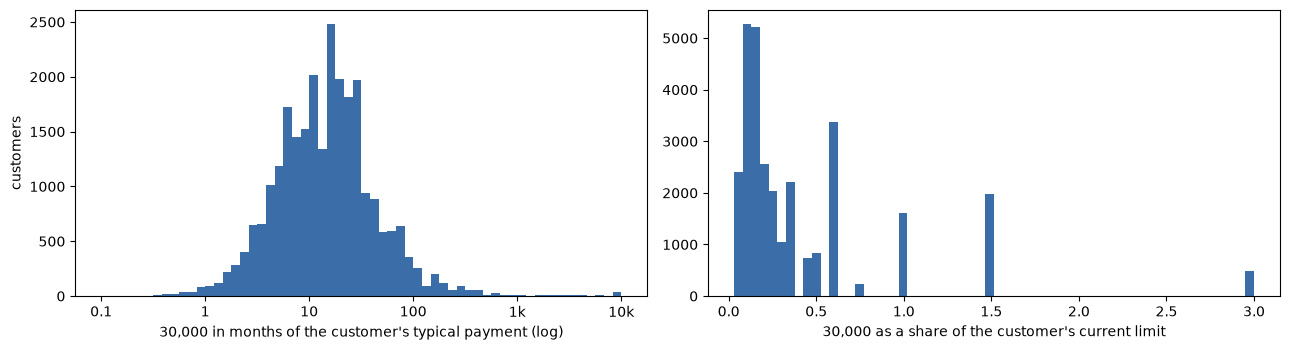

In [5]:
R_example = cfg["default_increase"]
rel = S.scenario_features(inp, R_example)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
pb = rel.scenario_payback_months.dropna()
ax[0].hist(np.log10(pb.clip(0.1, 1e4)), bins=60, color="#3b6ea8"); ax[0].set_xticks([-1, 0, 1, 2, 3, 4], ["0.1", "1", "10", "100", "1k", "10k"])
ax[0].set_xlabel(f"{R_example:,} in months of the customer's typical payment (log)"); ax[0].set_ylabel("customers")
ax[1].hist(rel.scenario_increase_to_limit.clip(upper=3.5), bins=60, color="#3b6ea8"); ax[1].set_xlabel(f"{R_example:,} as a share of the customer's current limit")
fig.tight_layout(); fig.savefig(C.FIGURES / "scenario_relativity.png", dpi=120)
pd.DataFrame({"payback months": pb.quantile([.05, .25, .5, .75, .95]), "share of limit": rel.scenario_increase_to_limit.quantile([.05, .25, .5, .75, .95])}).round(2).rename_axis("percentile")

**Relative scenarios.** Instead of one amount for everyone, the request can be set in each customer's own units: *k × their typical monthly payment* or *p × their current limit*.
Below: the share of customers in each band. With a relative request, customers are compared on their behaviour and risk, not on how big their numbers happen to be.

In [6]:
rows = {}
for k in cfg["relative_scenarios"]["payment_multiple"]:
    rows[f"{k}x typical payment"] = S.score(inp, S.relative_increase(inp, "payment_multiple", k), cfg)["band"].value_counts(normalize=True)
for p in cfg["relative_scenarios"]["limit_share"]:
    rows[f"{int(p*100)}% of limit"] = S.score(inp, S.relative_increase(inp, "limit_share", p), cfg)["band"].value_counts(normalize=True)
rel_sweep = pd.DataFrame(rows).fillna(0).loc[[S.BAND_SUPPORT, S.BAND_REVIEW, S.BAND_NOT, S.BAND_INSUFFICIENT]]
rel_sweep.to_csv(C.TABLES / "scenario_relative_sweep.csv"); rel_sweep.round(3)

,1x typical payment,3x typical payment,6x typical payment,12x typical payment,10% of limit,25% of limit,50% of limit
band,,,,,,,
Supportable in this scenario,0.637,0.625,0.604,0.472,0.600,0.509,0.279
Review,0.051,0.055,0.066,0.184,0.073,0.151,0.367
Not supportable in this scenario,0.135,0.143,0.153,0.167,0.150,0.163,0.177
Insufficient behavioural evidence,0.177,0.177,0.177,0.177,0.177,0.177,0.177


**Absolute vs relative request, by customer scale.** Share scored "supportable" among low-, mid- and high-limit customers:
* with the same absolute amount for everyone (30,000), small-scale customers are penalised just for being small;
* with a request of 3× their own typical payment, the gap between scales mostly reflects their behaviour and risk.

In [7]:
scale = pd.qcut(inp.credit_limit, 3, labels=["low-limit third", "mid-limit third", "high-limit third"])
comp_tab = pd.DataFrame({
    "absolute 30,000": (S.score(inp, 30000, cfg)["band"] == S.BAND_SUPPORT).groupby(scale, observed=True).mean(),
    "relative 3x own typical payment": (S.score(inp, S.relative_increase(inp, "payment_multiple", 3), cfg)["band"] == S.BAND_SUPPORT).groupby(scale, observed=True).mean(),
    "relative 25% of own limit": (S.score(inp, S.relative_increase(inp, "limit_share", 0.25), cfg)["band"] == S.BAND_SUPPORT).groupby(scale, observed=True).mean(),
})
comp_tab.round(3)

,"absolute 30,000",relative 3x own typical payment,relative 25% of own limit
credit_limit,,,
low-limit third,0.156,0.574,0.460
mid-limit third,0.536,0.627,0.522
high-limit third,0.645,0.681,0.552


## Full output for one example amount
**Score everyone for an example absolute increase of 30,000.** The result has the scenario features (prefixed `scenario_`), the sub-scores, each component's contribution, the final score, the band and any gate that applied.

In [8]:
R = cfg["default_increase"]
res = S.score(inp, R, cfg)
scored = inp.join(res.drop(columns="customer_id"))
res.band.value_counts().to_frame("customers").assign(share=lambda t: (t.customers / len(res)).round(3))

,customers,share
band,,
Supportable in this scenario,13025,0.434
Review,6158,0.205
Not supportable in this scenario,5512,0.184
Insufficient behavioural evidence,5305,0.177


**Score distribution** (customers stopped by a gate are shown separately).

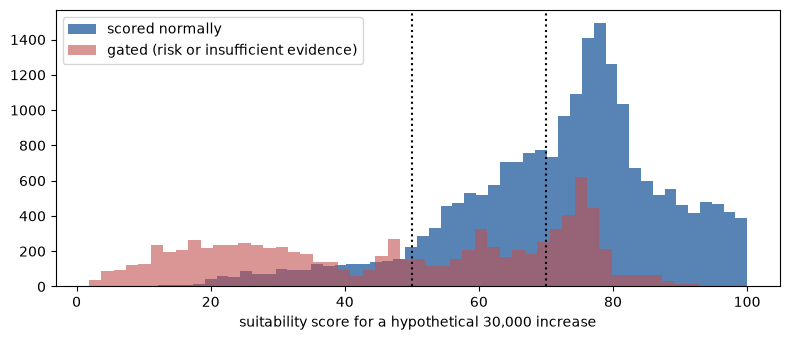

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(res.loc[res.gate == "", "score"], bins=50, color="#3b6ea8", alpha=.85, label="scored normally")
ax.hist(res.loc[res.gate != "", "score"], bins=50, color="#c0504d", alpha=.6, label="gated (risk or insufficient evidence)")
for v in [cfg["bands"]["review"], cfg["bands"]["supportable"]]: ax.axvline(v, color="k", ls=":")
ax.set_xlabel(f"suitability score for a hypothetical {R:,} increase"); ax.legend(); fig.tight_layout(); fig.savefig(C.FIGURES / "scenario_score_hist.png", dpi=120)

**Scenario sweep.** The same customers scored for 10k, 20k, 30k and 50k. Larger requests should move people *down* the bands, and more so for customers with small typical payments.

In [10]:
sweep = {}
for amt in cfg["scenario_amounts"]:
    sweep[f"{amt:,}"] = S.score(inp, amt, cfg)["band"].value_counts(normalize=True)
sweep = pd.DataFrame(sweep).fillna(0).loc[[S.BAND_SUPPORT, S.BAND_REVIEW, S.BAND_NOT, S.BAND_INSUFFICIENT]]
sweep.to_csv(C.TABLES / "scenario_sweep_bands.csv"); sweep.round(3)

,"10,000","20,000","30,000","50,000"
band,,,,
Supportable in this scenario,0.574,0.492,0.434,0.353
Review,0.091,0.159,0.205,0.265
Not supportable in this scenario,0.158,0.172,0.184,0.205
Insufficient behavioural evidence,0.177,0.177,0.177,0.177


**Same request, different context.** Median score by typical-payment group, for each request amount. The gap between groups shows that the absolute amount alone does not decide the outcome.

,"10,000","20,000","30,000","50,000"
pay_median,,,,
lowest 25% payers,68.5,62.5,59.5,57.6
2nd,75.6,69.3,64.5,57.3
3rd,82.7,78.9,75.8,70.7
highest 25% payers,86.4,84.3,82.6,79.4


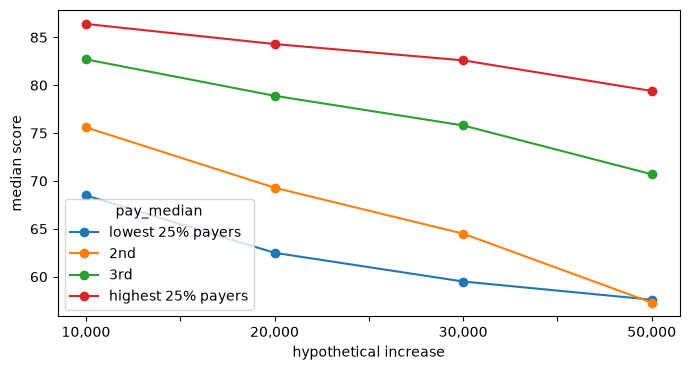

In [11]:
grp = pd.qcut(inp.pay_median.where(inp.pay_median > 0), 4, labels=["lowest 25% payers", "2nd", "3rd", "highest 25% payers"])
med = pd.DataFrame({f"{a:,}": S.score(inp, a, cfg)["score"].groupby(grp, observed=True).median() for a in cfg["scenario_amounts"]})
ax = med.T.plot(marker="o", figsize=(7, 3.8)); ax.set_ylabel("median score"); ax.set_xlabel("hypothetical increase")
plt.tight_layout(); plt.savefig(C.FIGURES / "scenario_by_payment_group.png", dpi=120); med.round(1)

**The senior's example on real customers.** We search for two actual customers who match on everything the score uses (same credit limit, almost the same predicted risk, similar payment coverage and utilization, no late months) but whose typical payments are roughly **20,000 vs 10,000**. Both get the same hypothetical 30,000 request.

In [12]:
base = scored[(scored.late_months == 0) & (scored.gate == "") & scored.credit_limit.between(100000, 300000)]
A_c = base[base.pay_median.between(15000, 25000)]; B_c = base[base.pay_median.between(7000, 13000)]
pairs = A_c.merge(B_c, on="credit_limit", suffixes=("_A", "_B"))
pairs = pairs[((pairs.pd_A - pairs.pd_B).abs() < 0.02) & ((pairs.coverage_median_A - pairs.coverage_median_B).abs() < 0.1)
              & ((pairs.util_latest_A - pairs.util_latest_B).abs() < 0.2)]   # match everything except typical payment
pairs["dist"] = (pairs.pay_median_A - 20000).abs() + (pairs.pay_median_B - 10000).abs() + 1e5 * (pairs.pd_A - pairs.pd_B).abs()
best = pairs.nsmallest(1, "dist").iloc[0]
cA, cB = int(best.customer_id_A), int(best.customer_id_B)
cols = ["customer_id", "credit_limit", "pd", "late_months", "coverage_median", "util_latest", "pay_median", "scenario_payback_months", "scenario_increase_to_limit", "score", "band"]
scored.set_index("customer_id").loc[[cA, cB]].reset_index()[cols].assign(who=["Customer A", "Customer B"]).set_index("who").round(3)

,customer_id,credit_limit,pd,late_months,coverage_median,util_latest,pay_median,scenario_payback_months,scenario_increase_to_limit,score,band
who,,,,,,,,,,,
Customer A,18724,160000.0,0.062,0,0.995,0.074,20000.0,1.500,0.188,99.1,Supportable in this scenario
Customer B,23329,160000.0,0.057,0,1.000,0.119,9995.0,3.002,0.188,97.0,Supportable in this scenario


**The same pair across request sizes** (the amount is configurable, so we add larger custom amounts too). At small requests both customers are comfortable, which is the relative logic working correctly. As the request grows, B's payback months grow twice as fast as A's and the scores separate: the same absolute request means something different for each.

payback_months            score                                 band                              
customer              A          B     A      B                             A                             B
increase                                                                                                   
10000               0.5     1.0005  99.9  100.0  Supportable in this scenario  Supportable in this scenario
30000               1.5   3.001501  99.1   97.0  Supportable in this scenario  Supportable in this scenario
50000               2.5   5.002501  97.0   94.4  Supportable in this scenario  Supportable in this scenario
100000              5.0  10.005003  91.4   86.5  Supportable in this scenario  Supportable in this scenario
150000              7.5  15.007504  86.0   81.1  Supportable in this scenario  Supportable in this scenario
200000             10.0  20.010005  82.1   77.2  Supportable in this scenario  Supportable in this scenario

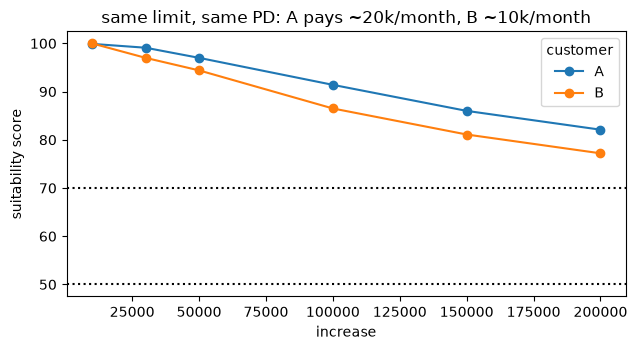

In [13]:
amounts = [10000, 30000, 50000, 100000, 150000, 200000]
pair = inp[inp.customer_id.isin([cA, cB])].set_index("customer_id").loc[[cA, cB]].reset_index()
rows = []
for amt in amounts:
    r = S.score(pair, amt, cfg)
    for who, i in [("A", 0), ("B", 1)]:
        rows.append({"increase": amt, "customer": who, "payback_months": r.scenario_payback_months[i], "score": r.score[i], "band": r.band[i]})
ab = pd.DataFrame(rows)
ab.to_csv(C.TABLES / "scenario_customer_A_vs_B.csv", index=False)
ax = ab.pivot(index="increase", columns="customer", values="score").plot(marker="o", figsize=(6.5, 3.6))
ax.axhline(cfg["bands"]["supportable"], color="k", ls=":"); ax.axhline(cfg["bands"]["review"], color="k", ls=":")
ax.set_ylabel("suitability score"); ax.set_title("same limit, same PD: A pays ~20k/month, B ~10k/month"); plt.tight_layout()
plt.savefig(C.FIGURES / "scenario_A_vs_B.png", dpi=120)
ab.pivot(index="increase", columns="customer", values=["payback_months", "score", "band"]).round(1)

**Explanation for Customer A.** Every number comes from a computed column. The graph-evidence lines are read from Neo4j.

In [14]:
def explain(cid, amount=R):
    row = scored.set_index("customer_id").loc[cid]; row["customer_id"] = cid
    r = S.score(inp[inp.customer_id == cid], amount, cfg).iloc[0]
    ev = S.graph_evidence(driver, cid, row)
    print(S.explain(row, r, cfg, ev))
explain(cA)

Customer 18724  |  SCENARIO: hypothetical credit increase of 30,000 (not an observed request)
Current limit 160,000 -> projected 190,000

Historical evidence (Apr-Sep 2005):
  average utilization 0.36 | latest utilization 0.07 | utilization trend -0.003/month
  median coverage of previous statement 0.99 | weak-coverage months 0/5
  late months 0/6 (last 3 months: 0) | latest status code 0
  typical (median) demonstrated monthly payment 20,000
Graph evidence (Neo4j):
  late in: none
  weak payment against previous statement in: none
  longest late streak 0 | relapses 0 | population P(late next month) 0.07
Scenario-relative evidence:
  request / current limit 0.19 | payback 1.5 months of typical payment
  projected utilization 0.06 (mechanical, assumes the bill stays the same; not scored)
Model: default probability 0.06 (calibrated, out-of-sample)

Suitability score 99/100  ->  Supportable in this scenario
  supports:       predicted default risk (calibrated) (+15.0); repayment record (l

**Explanation for Customer B at a larger request (100,000).** Same limit and risk as A; the request is now many months of B's demonstrated payments.

In [15]:
explain(cB, 100000)

Customer 23329  |  SCENARIO: hypothetical credit increase of 100,000 (not an observed request)
Current limit 160,000 -> projected 260,000

Historical evidence (Apr-Sep 2005):
  average utilization 0.08 | latest utilization 0.12 | utilization trend +0.011/month
  median coverage of previous statement 1.00 | weak-coverage months 0/5
  late months 0/6 (last 3 months: 0) | latest status code -1
  typical (median) demonstrated monthly payment 9,995
Graph evidence (Neo4j):
  late in: none
  weak payment against previous statement in: none
  longest late streak 0 | relapses 0 | population P(late next month) 0.06
Scenario-relative evidence:
  request / current limit 0.62 | payback 10.0 months of typical payment
  projected utilization 0.07 (mechanical, assumes the bill stays the same; not scored)
Model: default probability 0.06 (calibrated, out-of-sample)

Suitability score 86/100  ->  Supportable in this scenario
  supports:       predicted default risk (calibrated) (+15.0); repayment record 

**Customer A at the same 100,000**, for comparison.

In [16]:
explain(cA, 100000)

Customer 18724  |  SCENARIO: hypothetical credit increase of 100,000 (not an observed request)
Current limit 160,000 -> projected 260,000

Historical evidence (Apr-Sep 2005):
  average utilization 0.36 | latest utilization 0.07 | utilization trend -0.003/month
  median coverage of previous statement 0.99 | weak-coverage months 0/5
  late months 0/6 (last 3 months: 0) | latest status code 0
  typical (median) demonstrated monthly payment 20,000
Graph evidence (Neo4j):
  late in: none
  weak payment against previous statement in: none
  longest late streak 0 | relapses 0 | population P(late next month) 0.07
Scenario-relative evidence:
  request / current limit 0.62 | payback 5.0 months of typical payment
  projected utilization 0.05 (mechanical, assumes the bill stays the same; not scored)
Model: default probability 0.06 (calibrated, out-of-sample)

Suitability score 91/100  ->  Supportable in this scenario
  supports:       predicted default risk (calibrated) (+15.0); repayment record (

**A customer with a relapse pattern found by Cypher** (late → recovered → late again), to show the graph evidence in an explanation.

In [17]:
relapser = scored[(scored.g_relapses >= 1) & (scored.pd < 0.5)].sort_values("pd").iloc[len(scored[(scored.g_relapses >= 1) & (scored.pd < 0.5)]) // 2].customer_id
explain(int(relapser))

Customer 23653  |  SCENARIO: hypothetical credit increase of 30,000 (not an observed request)
Current limit 20,000 -> projected 50,000

Historical evidence (Apr-Sep 2005):
  average utilization 0.18 | latest utilization 0.00 | utilization trend +0.001/month
  median coverage of previous statement 0.50 | weak-coverage months 1/5
  late months 3/6 (last 3 months: 1) | latest status code 1
  typical (median) demonstrated monthly payment 788
Graph evidence (Neo4j):
  late in: 2005-05, 2005-06, 2005-09
  weak payment against previous statement in: 2005-06
  longest late streak 2 | relapses 1 | population P(late next month) 0.96
Scenario-relative evidence:
  request / current limit 1.50 | payback 38.1 months of typical payment
  projected utilization 0.00 (mechanical, assumes the bill stays the same; not scored)
Model: default probability 0.36 (calibrated, out-of-sample)

Suitability score 37/100  ->  Not supportable in this scenario
  supports:       payment coverage of previous statements 

## Validating a score that has no ground truth
**Check 1: automatic tests** (`tests/test_scoring.py`): direction checks on 3,000 real customers, demographic invariance, 8 golden personas, edge cases and traceability.

In [18]:
out = subprocess.run([sys.executable, "-m", "pytest", str(C.ROOT / "tests" / "test_scoring.py"), "-q", "-p", "no:warnings"], capture_output=True, text=True, cwd=C.ROOT)
print(out.stdout[-1500:])

.......................                                                  [100%]
23 passed in 1.65s



**Check 2: stability.** If the ranking of customers changed a lot when we nudge a weight by ±20% or a breakpoint by ±10%, the score would just be an artefact of arbitrary choices. We measure the rank correlation with the original score and the share of customers whose band changes.

In [19]:
ref = res
rows = []
for k in cfg["components"]:
    for f in (0.8, 1.2):
        w = {c: v["weight"] for c, v in cfg["components"].items()}; w[k] *= f
        tot = sum(w.values()); w = {c: v / tot for c, v in w.items()}
        r2 = S.score(inp, R, cfg, weights=w)
        rows.append({"change": f"weight {k} x{f}", "spearman_vs_original": spearmanr(ref.score, r2.score).statistic, "band_flips": (r2.band != ref.band).mean()})
    if "x" in cfg["components"][k]:
        for f in (0.9, 1.1):
            c2 = copy.deepcopy(cfg); c2["components"][k]["x"] = [x * f for x in c2["components"][k]["x"]]
            r2 = S.score(inp, R, c2)
            rows.append({"change": f"breakpoints {k} x{f}", "spearman_vs_original": spearmanr(ref.score, r2.score).statistic, "band_flips": (r2.band != ref.band).mean()})
stab = pd.DataFrame(rows).set_index("change"); stab.to_csv(C.TABLES / "scenario_stability.csv")
print(f"worst-case Spearman {stab.spearman_vs_original.min():.3f}, worst-case band flips {stab.band_flips.max():.1%}")
stab.round(3)

worst-case Spearman 0.997, worst-case band flips 3.0%


,spearman_vs_original,band_flips
change,,
weight model_risk x0.8,1.000,0.027
weight model_risk x1.2,1.000,0.021
breakpoints model_risk x0.9,1.000,0.019
breakpoints model_risk x1.1,1.000,0.016
weight repayment x0.8,0.999,0.023
weight repayment x1.2,1.000,0.020
weight coverage x0.8,0.997,0.023
weight coverage x1.2,0.997,0.022
breakpoints coverage x0.9,1.000,0.005


**Check 3: proxy check against the real outcome (test customers only).** Default is *not* suitability, so this cannot prove the score is right, but a sensible score should put fewer eventual defaulters in better bands.
We run it twice. The second version **removes the model-risk component** (weights re-normalised) so the check is not circular: it tests whether the behavioural and scenario components carry real risk information on their own.

In [20]:
test = scored[scored.split == "test"]
w_nopd = {k: v["weight"] for k, v in cfg["components"].items()}; w_nopd["model_risk"] = 0
w_nopd = {k: v / sum(w_nopd.values()) for k, v in w_nopd.items()}
no_pd = S.score(test, R, cfg, weights=w_nopd)
from sklearn.metrics import roc_auc_score
tabs = {}
for name, r in [("full score", test[["score", "band"]]), ("score without model risk", no_pd[["score", "band"]])]:
    t = ST.default_rate_table(r["band"], test[C.TARGET])[["n", "default_rate", "ci_low", "ci_high"]]
    order = [b for b in [S.BAND_SUPPORT, S.BAND_REVIEW, S.BAND_NOT, S.BAND_INSUFFICIENT] if b in t.index]
    tabs[name] = t.loc[order]
    print(f"{name}: ROC-AUC of (100 - score) for predicting default = {roc_auc_score(test[C.TARGET], 100 - r['score']):.3f}")
pd.concat(tabs, names=["version"])

full score: ROC-AUC of (100 - score) for predicting default = 0.756
score without model risk: ROC-AUC of (100 - score) for predicting default = 0.721


n  default_rate  ci_low  ci_high
version                  bucket                                                                
full score               Supportable in this scenario       2604        0.0945  0.0838   0.1063
                         Review                             1213        0.1566  0.1373   0.1782
                         Not supportable in this scenario   1105        0.5575  0.5280   0.5865
                         Insufficient behavioural evidence  1078        0.2551  0.2300   0.2820
score without model risk Supportable in this scenario       1638        0.0879  0.0751   0.1026
                         Review                             1754        0.1294  0.1145   0.1459
                         Not supportable in this scenario   1530        0.4451  0.4204   0.4701
                         Insufficient behavioural evidence  1078        0.2551  0.2300   0.2820

**Save** the scored table (30,000 scenario) for the final evaluation.

In [21]:
scored.drop(columns=[C.TARGET]).to_parquet(C.OUTPUTS / "scenario_scores_30k.parquet", index=False)
driver.close(); print("saved")

saved


### Takeaways
* **The customer's own historical scale decides how big a request is.** One example amount (30,000) ranges from ~2.6 months of typical payment (5th percentile) to ~92 months (95th percentile) across customers, and from 7% to 150% of their limit.
* **Absolute vs relative:** with the same absolute 30,000 for everyone, only ~16% of low-limit customers are "supportable" vs ~65% of high-limit ones. They are penalised just for being small. With a request of 3× *their own* typical payment, it is ~57% vs ~68%, and the remaining gap reflects behaviour and risk.
* **Scale invariance is tested:** multiplying a customer's limit, payments and request by the same factor leaves the scenario score unchanged. Only the ML default probability depends on absolute amounts, because it is learned from data.
* **Matched real pair** (same limit, risk, coverage and utilization; typical payments ~20k vs ~10k): the lower payer scores lower for the same request, and the gap widens as the request grows (2 points at 30k, 5 points at 100k–200k). Payback breakpoints follow the H10 default-rate gradient (≤1 month 4.6% … >30 months 28.6%).
* **Every explanation is traceable.** Contributions add up exactly to the score (tested). Graph evidence (late months, weak-payment months, streaks, relapses) comes straight from Neo4j.
* **Validation without ground truth:**
  - all automatic tests pass (direction, demographic invariance, 8 golden personas, edge cases, traceability);
  - nudging any weight by ±20% or any breakpoint by ±10% keeps the ranking almost identical (Spearman ≥ 0.997) and changes ≤ 3% of bands;
  - on test customers, eventual default rates rise from "supportable" (~9%) to "review" (~16%) to "not supportable" (~56%). **Even without the model-risk component** the ordering holds (~9% → ~13% → ~45%), so the behavioural and scenario parts carry real risk information.
* **About 18% of customers get "insufficient behavioural evidence"** (inactive accounts or no payments). Their default rate (~26%) is above average, which supports not rewarding inactivity.
* **Limits:**
  - the static-bill assumption behind projected utilization;
  - the request ÷ limit breakpoints are a policy assumption, not data-derived;
  - the dataset cannot tell us whether an increase would actually be repaid, so this remains a **demonstration of transparent reasoning, not an underwriting model**.